# k-nearest neighbours

[05_learning_to_split.ipynb](05_learning_to_split.ipynb) found a core of 912 compounds that every seed put on the hard test side. A random forest gets them right only 21% of the time even in random cross-validation; the learned test sides are chemically as familiar as random ones, so the difficulty is not novelty; and while no single descriptor tells the core from the rest, the 152 descriptors together find it with a held-out AUC of 0.77 — the representation sees *that* these compounds differ without placing them in the right tier. Is that because the descriptors cannot tell those compounds from compounds in other tiers (the representation), or because the models cannot use what the descriptors hold (the architecture)?

A k-nearest-neighbour model fits no function: it predicts a compound's tier distribution from the compounds closest to it. So it asks a representation directly whether compounds that look alike have alike solubility. Two compounds that are identical in a representation but sit in different tiers defeat every model on it; neighbours extend that from identical to nearly identical. That reading depends on what "near" means, so we sweep it, and we repeat it with three structural fingerprints, which see the molecule in a way the descriptors don't.

## Framework

- **Data and splits.** Unflagged votes with weight $1/n$ (flagged votes set aside), the compounds' tier distributions built from them, and three split schemes that keep a skeleton on one side: random and cluster 10-fold cross-validation from `data/aqsoldb_splits.csv`, and the five learned splits from `data/aqsoldb_splits_ls.csv`, which also carries the core.
- **Representations.**
  - *Descriptors*: the 152 chosen in [04_features.ipynb](04_features.ipynb), under two scalings (normal scores, as the learning-to-split networks see them, and z-scores, which leave heavy tails in place; missing values at the centre of each) and three distances (Euclidean, Manhattan, cosine). The scalings are fitted on all compounds; they don't use the labels.
  - *MAP4* (Capecchi, Probst & Reymond 2020): the set of atom pairs, each written as the two atoms' circular environments (radius 1 and 2) and the bond distance between them, MinHashed to 1024 values. Distance: the share of MinHash values that differ, an estimate of 1 − the Jaccard similarity of the two sets.
  - *Morgan counts, radius 3 and radius 9*: how many times each circular environment up to that radius occurs, unfolded (no hashing collisions). Distance: 1 − Tanimoto on counts (the sum of the smaller counts over the sum of the larger). Radius 3 sees environments up to six bonds across; radius 9 adds much larger ones, which in most molecules are close to the whole molecule.
  - All three fingerprints are computed on the whole compound, counter-ions included, as the descriptors are.
- **The model.** A compound's predicted tier distribution is the mean of its $k$ nearest train compounds' tier distributions (optionally weighted by 1/distance). A compound counts once however many votes it has.
- **Selection.** For each representation, each setting ($k$, weights, and for the descriptors the scaling and distance) is scored on the validation side of each random cross-validation split; the setting with the best mean information is chosen. Only then is it scored on test sides, so the test score is not inflated by the choice.
- **Scores.** From `scripts/aqsoldb_harness.py`, as in the other notebooks: information $= H(T) - \text{log-loss}$ of the predicted tier distribution shrunk toward uniform with $\lambda$ chosen on the validation side (floor 0.005), plus the hard-tier accuracies. Cross-validation schemes show the mean over splits ± the standard error corrected for overlapping training sets; learning to split shows the mean ± standard deviation over seeds.

In [1]:
import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator, rdMHFPFingerprint
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import QuantileTransformer, StandardScaler

RDLogger.DisableLog("rdApp.warning")  # e.g. "not removing hydrogen atom without neighbors" for H2 and hydrides
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from aqsoldb_harness import METRICS, calibrate, corrected_se, formatted, score  # noqa: E402

votes = pd.read_csv(ROOT / "data" / "aqsoldb_tiers.csv")  # one row per vote: tier, weight, flag
values = votes[votes["weight"] > 0].reset_index(drop=True)  # flagged votes carry weight zero: set aside
TIERS = int(values["tier"].max()) + 1
splits = pd.read_csv(ROOT / "data" / "aqsoldb_splits.csv", index_col="InChIKey")  # one row per compound
learned = pd.read_csv(ROOT / "data" / "aqsoldb_splits_ls.csv", index_col="InChIKey").reindex(splits.index)
features = pd.read_csv(ROOT / "data" / "aqsoldb_features.csv", index_col="InChIKey").reindex(splits.index)
CV_SPLITS = [c for c in splits.columns if c.startswith("cv_") and c[3:].isdigit()]
CLUSTER_SPLITS = [c for c in splits.columns if c.startswith("cluster_") and c[8:].isdigit()]
LS_SPLITS = [c for c in learned.columns if c.startswith("ls_") and c[3:].isdigit()]
SCHEMES = {"random cross-validation": CV_SPLITS, "cluster cross-validation": CLUSTER_SPLITS, "learning to split": LS_SPLITS}
all_splits = splits.join(learned[LS_SPLITS])
assert LS_SPLITS, "run 05_learning_to_split.ipynb first"

X = features.to_numpy()  # one row per compound
compound = splits.index.get_indexer(values["InChIKey"])  # vote row -> compound
assert (compound >= 0).all(), "a vote's compound is missing from the splits"
y, w = values["tier"].to_numpy(), values["weight"].to_numpy()
n_compounds = len(splits)
repeated = np.bincount(compound, minlength=n_compounds) > 1  # compounds with 2+ unflagged votes
in_tests, core = learned["ls_test_count"].to_numpy(), learned["ls_core"].to_numpy().astype(bool)
mols = [Chem.MolFromSmiles(s) for s in values.groupby("InChIKey")["SMILES"].first().reindex(splits.index)]
assert all(mols), "a SMILES failed to parse"

# Each compound's tier distribution: the share of its unflagged votes in each tier (weights sum to 1 per compound).
tier_share = np.zeros((n_compounds, TIERS))
np.add.at(tier_share, (compound, y), w)
assert np.allclose(tier_share.sum(axis=1), 1)


def calibrate_on(proba: np.ndarray, on: np.ndarray) -> float:
    """λ chosen on every vote of the compounds in `on` (a mask over compounds)."""
    r = on[compound]
    return calibrate(y[r], proba[compound[r]], w[r])


def evaluate(proba: np.ndarray, on: np.ndarray, lam: float) -> dict:
    """Scores of a tier distribution per compound over every vote of the compounds in `on`."""
    r = on[compound]
    return score(y[r], proba[compound[r]], w[r], lam)


print(f"{len(values)} votes, {n_compounds} compounds, {X.shape[1]} features; {len(CV_SPLITS)} random, {len(CLUSTER_SPLITS)} cluster "
      f"and {len(LS_SPLITS)} learned splits; core of {core.sum()} compounds")

12013 votes, 9946 compounds, 152 features; 10 random, 10 cluster and 5 learned splits; core of 912 compounds


## Representations

Each representation becomes a matrix of distances between every pair of compounds; the neighbours are read from it.

MAP4's reference code ([github.com/reymond-group/map4](https://github.com/reymond-group/map4), MIT licence) doesn't install on this Python: its setup uses `distutils`, and it hashes with `tmap`, which is only on conda. The shingles below follow that code (radius 2, not counted); the MinHash is RDKit's port of the same group's MHFP encoder (1024 permutations, seed 42) in place of `tmap`'s, which estimates the same Jaccard similarity.

MAP4 builds its pairs from atoms' bonded environments, so an isolated atom or ion contributes nothing: every simple inorganic salt (CsCl, LiBr, …) gets the same fingerprint, as does every single-atom compound. The reference's command-line tool goes further and keeps only the largest fragment. The table below counts, per representation, the compounds identical to at least one other compound.

In [2]:
MAP4_RADIUS, MAP4_DIMENSIONS = 2, 1024  # MAP4 defaults
MORGAN_RADII = [3, 9]


def environments(mol) -> list[list[str]]:
    """Per atom, the rooted SMILES of its circular environment at each radius 1 .. MAP4_RADIUS ('' if it has none)."""
    rows = []
    for idx in range(mol.GetNumAtoms()):
        row = []
        for radius in range(1, MAP4_RADIUS + 1):
            atom_map = {}
            submol = Chem.PathToSubmol(mol, Chem.FindAtomEnvironmentOfRadiusN(mol, radius, idx), atomMap=atom_map)
            row.append(Chem.MolToSmiles(submol, rootedAtAtom=atom_map[idx], canonical=True, isomericSmiles=False) if idx in atom_map else "")
        rows.append(row)
    return rows


def map4_shingles(mol) -> list[str]:
    """MAP4's shingles: per pair of atoms and radius, the two environments (sorted) and the bond distance between them."""
    env, dist = environments(mol), Chem.GetDistanceMatrix(mol)  # disconnected fragments are 1e8 apart, as in the reference
    shingles = set()
    for a, b in itertools.combinations(range(mol.GetNumAtoms()), 2):
        for r in range(MAP4_RADIUS):
            first, second = sorted([env[a][r], env[b][r]])
            shingles.add(f"{first}|{int(dist[a][b])}|{second}")
    return sorted(shingles)


encoder = rdMHFPFingerprint.MHFPEncoder(MAP4_DIMENSIONS, 42)
shingles = [map4_shingles(m) for m in mols]
no_pairs = np.array([not s for s in shingles])  # single atoms: no pairs, so all such compounds get the same fingerprint
map4 = np.array([list(encoder.FromStringArray(s)) for s in shingles], dtype=np.uint32)


def tanimoto_distances(fps: list) -> np.ndarray:
    """1 - Tanimoto between every pair of count fingerprints (sum of smaller counts / sum of larger)."""
    return 1 - np.array([DataStructs.BulkTanimotoSimilarity(fp, fps) for fp in fps], dtype=np.float32)


SCALINGS = {
    "normal scores": np.nan_to_num(QuantileTransformer(output_distribution="normal", random_state=0).fit_transform(X)),
    "z-scores": np.nan_to_num(StandardScaler().fit_transform(X)),  # StandardScaler ignores missing values when fitting
}
DISTANCES = ["euclidean", "manhattan", "cosine"]
REPRESENTATIONS = {  # (representation, variant) -> distance between every pair of compounds
    **{("descriptors", f"{scaling}, {d}"): pairwise_distances(x, metric=d, n_jobs=-1).astype(np.float32)
       for (scaling, x), d in itertools.product(SCALINGS.items(), DISTANCES)},
    ("MAP4", "MinHash distance"): pairwise_distances(map4, metric="hamming", n_jobs=-1).astype(np.float32),
    **{(f"Morgan counts, radius {r}", "1 - Tanimoto"): tanimoto_distances(
        [rdFingerprintGenerator.GetMorganGenerator(radius=r).GetSparseCountFingerprint(m) for m in mols]) for r in MORGAN_RADII},
}
FINGERPRINTS = ["MAP4", *[f"Morgan counts, radius {r}" for r in MORGAN_RADII]]
print(f"{no_pairs.sum()} compounds with a single atom (no MAP4 atom pairs)")
pd.DataFrame(
    {"median distance": [np.median(D) for D in REPRESENTATIONS.values()],
     "compounds identical to another": [int(((D < 1e-6).sum(axis=1) > 1).sum()) for D in REPRESENTATIONS.values()]},
    index=pd.MultiIndex.from_tuples(REPRESENTATIONS, names=["representation", "variant"]),
).round(3)

37 compounds with a single atom (no MAP4 atom pairs)


median distance  \
representation          variant                                     
descriptors             normal scores, euclidean        35.039001   
                        normal scores, manhattan       237.078995   
                        normal scores, cosine            0.276000   
                        z-scores, euclidean             13.739000   
                        z-scores, manhattan             87.782997   
                        z-scores, cosine                 1.018000   
MAP4                    MinHash distance                 1.000000   
Morgan counts, radius 3 1 - Tanimoto                     0.951000   
Morgan counts, radius 9 1 - Tanimoto                     0.959000   

                                                  compounds identical to another  
representation          variant                                                   
descriptors             normal scores, euclidean                             142  
                        normal scores, manhattan                             142  
                        normal scores, cosine                                164  
                        z-scores, euclidean                                  152  
                        z-scores, manhattan                                  152  
                        z-scores, cosine                                     156  
MAP4                    MinHash distance                                     511  
Morgan counts, radius 3 1 - Tanimoto                                         536  
Morgan counts, radius 9 1 - Tanimoto                                         532

## The sweep

A neighbour-based verdict on a representation is only as good as the neighbours, so each representation first gets the $k$, weighting and (for the descriptors) scaling and distance that predict best on the validation sides of the random splits, with $\lambda$ chosen on those same sides. The table shows the chosen setting for each representation; the plots show them all.

In [3]:
KS = [1, 3, 5, 10, 20, 50, 100]
WEIGHTS = ["uniform", "1/distance"]


def test_to_train(split_list: list[str]) -> float:
    return (all_splits[split_list[0]] == "test").sum() / (all_splits[split_list[0]] == "train").sum()


def validation_to_train(split_list: list[str]) -> float:
    return (all_splits[split_list[0]] == "validation").sum() / (all_splits[split_list[0]] == "train").sum()


def neighbors(D: np.ndarray, train: np.ndarray, query: np.ndarray, k: int = max(KS)) -> tuple[np.ndarray, np.ndarray]:
    """Distances to, and tier distributions of, each query compound's k nearest train compounds, nearest first."""
    d = D[np.ix_(query, train)]
    idx = np.argpartition(d, k, axis=1)[:, :k]
    idx = np.take_along_axis(idx, np.take_along_axis(d, idx, axis=1).argsort(axis=1), axis=1)
    return np.take_along_axis(d, idx, axis=1), tier_share[np.flatnonzero(train)[idx]]


def vote(dist: np.ndarray, shares: np.ndarray, k: int, weights: str) -> np.ndarray:
    """Predicted tier distribution: the mean of the k nearest compounds' tier distributions, weighted if asked."""
    wt = np.ones_like(dist[:, :k]) if weights == "uniform" else 1 / np.maximum(dist[:, :k], 1e-9)
    return (wt[:, :, None] * shares[:, :k]).sum(axis=1) / wt.sum(axis=1, keepdims=True)


rows = []
for (representation, variant), split in itertools.product(REPRESENTATIONS, CV_SPLITS):
    side = all_splits[split].to_numpy()
    validation = side == "validation"
    dist, shares = neighbors(REPRESENTATIONS[representation, variant], side == "train", validation)  # largest k, then sliced
    for k, weights in itertools.product(KS, WEIGHTS):
        proba = np.full((n_compounds, TIERS), 1 / TIERS)
        proba[validation] = vote(dist, shares, k, weights)
        lam = calibrate_on(proba, validation)
        rows.append({"representation": representation, "variant": variant, "weights": weights, "k": k, "split": split, "λ": lam,
                     **evaluate(proba, validation, lam)})

SETTING = ["representation", "variant", "weights", "k"]
by_setting = pd.DataFrame(rows).groupby(SETTING)
sweep = by_setting["information (bits)"].agg(["mean", "var"])
sweep["SE"] = np.sqrt((1 / len(CV_SPLITS) + validation_to_train(CV_SPLITS)) * sweep.pop("var"))
sweep["accuracy: same tier (%)"] = by_setting["accuracy: same tier (%)"].mean()
sweep = sweep.rename(columns={"mean": "validation information (bits)"}).sort_index()
chosen = sweep.loc[[(rep, *sweep.loc[rep, "validation information (bits)"].idxmax()) for rep in dict.fromkeys(r for r, _ in REPRESENTATIONS)]]
BEST = {rep: dict(zip(SETTING, setting)) for rep, setting in zip(chosen.index.get_level_values(0), chosen.index)}
chosen.round(3)

,,,,validation information (bits),SE,accuracy: same tier (%)
representation,variant,weights,k,,,
descriptors,"z-scores, manhattan",1/distance,20,0.856,0.018,68.204
MAP4,MinHash distance,1/distance,10,0.673,0.025,62.820
"Morgan counts, radius 3",1 - Tanimoto,1/distance,20,0.717,0.015,63.391
"Morgan counts, radius 9",1 - Tanimoto,1/distance,20,0.702,0.015,62.773


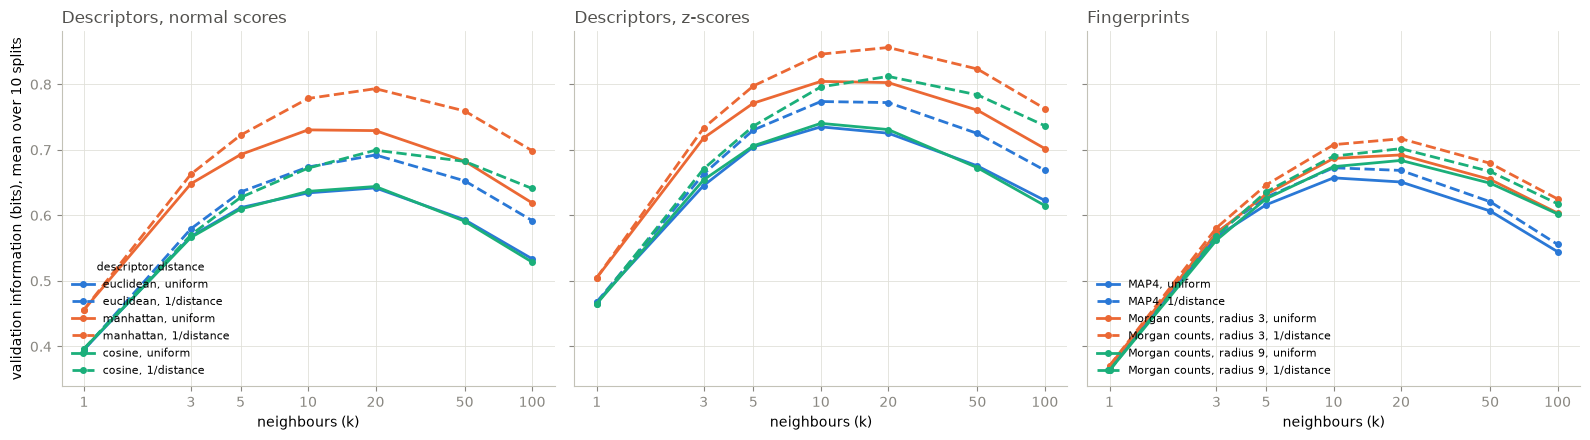

In [4]:
INK, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"  # as in 01_prep_and_analysis.ipynb
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical order
DASH = {"uniform": "-", "1/distance": "--"}


def style(ax):
    """Recessive axes and grid."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set(xscale="log", xticks=KS, xticklabels=KS, xlabel="neighbours (k)")
    ax.minorticks_off()


def plot_lines(ax, representation: str, variants: list[str], label):
    """One line per variant and weighting: validation information against k."""
    for (variant, color), weights in itertools.product(zip(variants, COLORS), WEIGHTS):
        info = sweep.loc[(representation, variant, weights), "validation information (bits)"]
        ax.plot(info.index, info, color=color, ls=DASH[weights], lw=2, marker="o", ms=4, label=label(variant, weights))
    style(ax)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, scaling in zip(axes, SCALINGS):
    plot_lines(ax, "descriptors", [f"{scaling}, {d}" for d in DISTANCES], lambda v, wt: f"{v.split(', ')[1]}, {wt}")
    ax.set_title(f"Descriptors, {scaling}", loc="left", color=INK)
ax = axes[2]
for representation, color in zip(FINGERPRINTS, COLORS):
    for weights in WEIGHTS:
        info = sweep.loc[(representation, slice(None), weights), "validation information (bits)"].droplevel([0, 1, 2])
        ax.plot(info.index, info, color=color, ls=DASH[weights], lw=2, marker="o", ms=4, label=f"{representation}, {weights}")
style(ax)
ax.set_title("Fingerprints", loc="left", color=INK)
ax.legend(frameon=False, loc="lower left", fontsize=8)
axes[0].set_ylabel("validation information (bits), mean over 10 splits")
axes[0].legend(frameon=False, loc="lower left", fontsize=8, title="descriptor distance", title_fontsize=8)
fig.tight_layout()

## Against the random forest, on three kinds of split

Each representation's chosen setting, and the features notebook's random forest on the descriptors, each trained on a split's train side, calibrated on its validation side and scored on its test side — on the random, cluster and learned splits. If a fingerprint held up on the learned test sides where the descriptors fall, those splits would be hard because of what the descriptors leave out. Two test populations, as before: all test compounds, and those with 2+ unflagged votes (the repeat-measurement benchmark on all such compounds is 0.963 bits, 76.5% in the same tier, held out).

In [5]:
RF_SETTINGS = dict(n_estimators=500, n_jobs=-1, random_state=0)  # as in 04_features.ipynb
SUBSETS = {"all test compounds": np.ones(n_compounds, bool), "test compounds with 2+ unflagged votes": repeated}


def knn_proba(representation: str):
    """Tier distribution per compound on the validation and test sides, from the representation's chosen setting."""
    best = BEST[representation]

    def predict(train: np.ndarray, query: np.ndarray) -> np.ndarray:
        proba = np.full((n_compounds, TIERS), 1 / TIERS)
        dist, shares = neighbors(REPRESENTATIONS[representation, best["variant"]], train, query, best["k"])
        proba[query] = vote(dist, shares, best["k"], best["weights"])
        return proba

    return predict


def forest_proba(train: np.ndarray, query: np.ndarray) -> np.ndarray:
    """Tier distribution per compound from a forest trained on every vote of the train compounds, each compound weighted once."""
    rows = train[compound]
    model = RandomForestClassifier(**RF_SETTINGS).fit(X[compound[rows]], y[rows], sample_weight=w[rows])
    assert list(model.classes_) == list(range(TIERS)), "a tier is missing from the training rows"
    return model.predict_proba(X)


PREDICTORS = {**{f"kNN on {rep} (k = {best['k']})": knn_proba(rep) for rep, best in BEST.items()}, "random forest on descriptors": forest_proba}

rows = []
for name, predict in PREDICTORS.items():
    for scheme, split_list in SCHEMES.items():
        for split in split_list:
            side = all_splits[split].to_numpy()
            train, validation, test = side == "train", side == "validation", side == "test"
            assert train.any() and validation.any() and test.any(), f"{split}: a side has no rows"
            proba = predict(train, validation | test)
            lam = calibrate_on(proba, validation)
            for subset, mask in SUBSETS.items():
                rows.append({"predictor": name, "scheme": scheme, "split": split, "subset": subset, **evaluate(proba, test & mask, lam)})
held_out = pd.DataFrame(rows)

tables = {}
for name in PREDICTORS:
    blocks = {}
    for scheme, split_list in SCHEMES.items():
        d = held_out[(held_out["predictor"] == name) & (held_out["scheme"] == scheme)]
        by = d.groupby("subset", sort=False)[list(METRICS)]
        if scheme == "learning to split":
            blocks[f"{scheme} (mean ± SD)"] = formatted(by.mean()) + " ± " + formatted(by.std())
        else:
            se = by.apply(lambda g: g.apply(corrected_se, n_splits=len(split_list), test_to_train=test_to_train(split_list)))
            blocks[f"{scheme} (mean ± SE)"] = formatted(by.mean()) + " ± " + formatted(se)
    tables[name] = pd.concat(blocks, names=["split", "subset"])
pd.concat(tables, names=["predictor"])[["information (bits)", "accuracy: same tier (%)", "1 tier off (%)", "2+ tiers off (%)"]]

information (bits)  \
predictor                               split                                subset                                                      
kNN on descriptors (k = 20)             random cross-validation (mean ± SE)  all test compounds                          0.858 ± 0.019   
                                                                             test compounds with 2+ unflagged votes      0.813 ± 0.056   
                                        cluster cross-validation (mean ± SE) all test compounds                          0.781 ± 0.025   
                                                                             test compounds with 2+ unflagged votes      0.747 ± 0.050   
                                        learning to split (mean ± SD)        all test compounds                         -0.982 ± 0.203   
                                                                             test compounds with 2+ unflagged votes     -0.619 ± 0.155   
kNN on MAP4 (k = 10)                    random cross-validation (mean ± SE)  all test compounds                          0.663 ± 0.023   
                                                                             test compounds with 2+ unflagged votes      0.629 ± 0.045   
                                        cluster cross-validation (mean ± SE) all test compounds                          0.567 ± 0.021   
                                                                             test compounds with 2+ unflagged votes      0.555 ± 0.058   
                                        learning to split (mean ± SD)        all test compounds                         -0.902 ± 0.141   
                                                                             test compounds with 2+ unflagged votes     -0.587 ± 0.112   
kNN on Morgan counts, radius 3 (k = 20) random cross-validation (mean ± SE)  all test compounds                          0.711 ± 0.015   
                                                                             test compounds with 2+ unflagged votes      0.671 ± 0.045   
                                        cluster cross-validation (mean ± SE) all test compounds                          0.637 ± 0.028   
                                                                             test compounds with 2+ unflagged votes      0.624 ± 0.055   
                                        learning to split (mean ± SD)        all test compounds                         -0.810 ± 0.126   
                                                                             test compounds with 2+ unflagged votes     -0.530 ± 0.055   
kNN on Morgan counts, radius 9 (k = 20) random cross-validation (mean ± SE)  all test compounds                          0.696 ± 0.015   
                                                                             test compounds with 2+ unflagged votes      0.657 ± 0.045   
                                        cluster cross-validation (mean ± SE) all test compounds                          0.621 ± 0.029   
                                                                             test compounds with 2+ unflagged votes      0.609 ± 0.054   
                                        learning to split (mean ± SD)        all test compounds                         -0.819 ± 0.117   
                                                                             test compounds with 2+ unflagged votes     -0.526 ± 0.081   
random forest on descriptors            random cross-validation (mean ± SE)  all test compounds                          1.009 ± 0.009   
                                                                             test compounds with 2+ unflagged votes      0.991 ± 0.041   
                                        cluster cross-validation (mean ± SE) all test compounds                          0.941 ± 0.025   
                                                                             test compounds with 2+ unflagged vote

- **The sweep.** On the descriptors, Manhattan distance on z-scores with 1/distance weights is best, at $k = 20$ (0.856 bits on validation). Each fingerprint is best with 1/distance weights at $k = 10$–20: Morgan counts at radius 3 (0.717 bits), radius 9 (0.702) and MAP4 (0.673). Going from radius 3 to 9 adds nothing.
- **Neighbours on fingerprints share less about the tier than neighbours on descriptors.** On the random test sides the neighbours carry 0.86 bits on descriptors and 0.66–0.71 on fingerprints; the forest on descriptors carries 1.01. The cluster splits cost every representation a similar 0.07–0.10 bits, so unfamiliar chemistry is not what separates them.
- **The learned splits are hard for every representation.** They were learned on descriptors, yet on the fingerprints the neighbours fall just as far, to −0.8 to −0.9 bits (negative: the neighbours give the measured tier less probability than a uniform guess would — the LS notebook explains the sign), against −1.0 on descriptors and −0.6 for the forest; the most probable tier is right about 26% of the time for every neighbour model and 24% for the forest. If the descriptors were hiding a structural difference that a fingerprint sees, a fingerprint would hold up here; none does. The neighbour models are, if anything, *more* confidently wrong than the forest: their neighbours vote near-unanimously for another tier.

## What the neighbours say about each compound

The scores above are averages over test sides. To get back to the core, we ask the neighbours about each compound in turn.

Each compound is on the test side of exactly one random split, so its $k$ nearest neighbours among that split's train compounds (never its own skeleton) are well defined. Two numbers per compound, from each representation's chosen setting:

- **agreement with it**: the chance that a random vote of a random neighbour is in the same tier as a random vote of the compound (weighted as the vote is);
- **neighbours' top tier**: the share of the neighbours' votes in their most common tier.

Each compound then falls in one of three patterns:

| Pattern | Rule | Reading |
|---|---|---|
| neighbours agree with it | agreement ≥ 0.5 | the representation places it among its own tier |
| neighbours agree on another tier | agreement < 0.5, top tier ≥ 0.5 | it is the odd one out: noise, a condition the structure doesn't record, or a difference the representation misses |
| neighbours mixed | both < 0.5 | its region mixes tiers: the representation can't tell them apart |

The first table groups compounds by how many learned test sides they are in (5 = the core) and shows each representation's patterns. The last columns give the mean distance to the $k$ neighbours divided by its median over all compounds (above 1: a sparser region than usual).

In [6]:
PATTERNS = ["neighbours agree with it", "neighbours agree on another tier", "neighbours mixed"]
count_index = pd.Series(in_tests, name="learned test sides it is in")
pattern, spacing, top_tier = {}, {}, {}
for representation, best in BEST.items():
    neighbour_share, spacing[representation] = np.zeros((n_compounds, TIERS)), np.zeros(n_compounds)
    for split in CV_SPLITS:
        side = all_splits[split].to_numpy()
        test = side == "test"
        dist, shares = neighbors(REPRESENTATIONS[representation, best["variant"]], side == "train", test, best["k"])
        neighbour_share[test], spacing[representation][test] = vote(dist, shares, best["k"], best["weights"]), dist.mean(axis=1)
    agreement = (tier_share * neighbour_share).sum(axis=1)
    top_tier[representation] = neighbour_share.argmax(axis=1)
    pattern[representation] = pd.Series(np.select([agreement >= 0.5, neighbour_share.max(axis=1) >= 0.5], PATTERNS[:2], PATTERNS[2]))

shares_by_count = pd.concat(
    {rep: 100 * pd.crosstab(count_index, p, normalize="index")[PATTERNS] for rep, p in pattern.items()}, axis=1, names=["representation", "%"]
)
distance_by_count = pd.concat({rep: pd.Series(s / np.median(s)).groupby(count_index).median() for rep, s in spacing.items()}, axis=1)
distance_by_count.columns = pd.MultiIndex.from_product([["relative neighbour distance (median)"], distance_by_count.columns])
shares_by_count.insert(0, ("", "compounds"), count_index.value_counts().sort_index())
shares_by_count.join(distance_by_count).round(1).T

learned test sides it is in                                                 0  \
                                     compounds                         5803.0   
descriptors                          neighbours agree with it            77.6   
                                     neighbours agree on another tier    10.2   
                                     neighbours mixed                    12.2   
MAP4                                 neighbours agree with it            68.5   
                                     neighbours agree on another tier    13.5   
                                     neighbours mixed                    18.0   
Morgan counts, radius 3              neighbours agree with it            68.0   
                                     neighbours agree on another tier    11.2   
                                     neighbours mixed                    20.9   
Morgan counts, radius 9              neighbours agree with it            66.8   
                                     neighbours agree on another tier    12.3   
                                     neighbours mixed                    20.9   
relative neighbour distance (median) descriptors                          1.0   
                                     MAP4                                 1.0   
                                     Morgan counts, radius 3              1.0   
                                     Morgan counts, radius 9              1.0   

learned test sides it is in                                                 1  \
                                     compounds                         1256.0   
descriptors                          neighbours agree with it            52.9   
                                     neighbours agree on another tier    24.9   
                                     neighbours mixed                    22.2   
MAP4                                 neighbours agree with it            44.1   
                                     neighbours agree on another tier    30.4   
                                     neighbours mixed                    25.5   
Morgan counts, radius 3              neighbours agree with it            41.4   
                                     neighbours agree on another tier    23.6   
                                     neighbours mixed                    35.0   
Morgan counts, radius 9              neighbours agree with it            40.4   
                                     neighbours agree on another tier    23.5   
                                     neighbours mixed                    36.1   
relative neighbour distance (median) descriptors                          1.0   
                                     MAP4                                 1.0   
                                     Morgan counts, radius 3              1.0   
                                     Morgan counts, radius 9              1.0   

learned test sides it is in                                                2  \
                                     compounds                         796.0   
descriptors                          neighbours agree with it           38.6   
                                     neighbours agree on another tier   36.7   
                                     neighbours mixed                   24.7   
MAP4                                 neighbours agree with it           36.2   
                                     neighbours agree on another tier   36.9   
                                     neighbours mixed                   26.9   
Morgan counts, radius 3              neighbours agree with it           30.8   
                                     neighbours agree on another tier   34.3   
                                     neighbours mixed                   34.9   
Morgan counts, radius 9              neighbours agree with it           31.7   
                                     neighbours agree on another tier   32.9   
                                     neigh

### Do the fingerprints agree with the descriptors about the core?

For the core compounds only: rows are the pattern of their descriptor neighbours, columns the pattern of their neighbours under each fingerprint, as counts. The two cells that matter most:

- descriptor neighbours on **another tier**, fingerprint neighbours **agree with it**: structural analogues back up the compound's value, so the descriptors are missing a difference that matters;
- descriptor neighbours on **another tier**, fingerprint neighbours **also on another tier**: both views of the structure put it elsewhere, so the value, or a condition the structure doesn't record, is the likelier explanation.

The printed line checks that second cell: how often the fingerprint neighbours' top tier is the same as the descriptor neighbours'.

In [7]:
descriptor_pattern = pattern["descriptors"][core].rename("descriptor neighbours")
for fp in FINGERPRINTS:
    both = core & (pattern["descriptors"] == PATTERNS[1]).to_numpy() & (pattern[fp] == PATTERNS[1]).to_numpy()
    same = (top_tier[fp][both] == top_tier["descriptors"][both]).mean()
    print(f"{fp}: both on another tier for {both.sum()} core compounds; the same other tier for {100 * same:.0f}%")
pd.concat(
    {fp: pd.crosstab(descriptor_pattern, pattern[fp][core].rename("fingerprint neighbours")).reindex(index=PATTERNS, columns=PATTERNS, fill_value=0)
     for fp in FINGERPRINTS},
    axis=1,
)

MAP4: both on another tier for 351 core compounds; the same other tier for 93%
Morgan counts, radius 3: both on another tier for 363 core compounds; the same other tier for 95%
Morgan counts, radius 9: both on another tier for 355 core compounds; the same other tier for 95%


MAP4  \
fingerprint neighbours           neighbours agree with it   
descriptor neighbours                                       
neighbours agree with it                               73   
neighbours agree on another tier                       41   
neighbours mixed                                       45   

                                                                   \
fingerprint neighbours           neighbours agree on another tier   
descriptor neighbours                                               
neighbours agree with it                                       39   
neighbours agree on another tier                              351   
neighbours mixed                                               93   

                                                   Morgan counts, radius 3  \
fingerprint neighbours           neighbours mixed neighbours agree with it   
descriptor neighbours                                                        
neighbours agree with it                       30                       63   
neighbours agree on another tier              116                       18   
neighbours mixed                              124                       29   

                                                                   \
fingerprint neighbours           neighbours agree on another tier   
descriptor neighbours                                               
neighbours agree with it                                       30   
neighbours agree on another tier                              363   
neighbours mixed                                               91   

                                                   Morgan counts, radius 9  \
fingerprint neighbours           neighbours mixed neighbours agree with it   
descriptor neighbours                                                        
neighbours agree with it                       49                       68   
neighbours agree on another tier              127                       24   
neighbours mixed                              142                       27   

                                                                   \
fingerprint neighbours           neighbours agree on another tier   
descriptor neighbours                                               
neighbours agree with it                                       23   
neighbours agree on another tier                              355   
neighbours mixed                                               85   

                                                   
fingerprint neighbours           neighbours mixed  
descriptor neighbours                              
neighbours agree with it                       51  
neighbours agree on another tier              129  
neighbours mixed                              150

In [8]:
# Hand-off for the front notebook: each predictor's held-out information per scheme and population, with its description
# length. A neighbour model's "model" is its training set, so its length is train compounds × stored numbers per compound.
dims = {
    "descriptors": X.shape[1],
    "MAP4": MAP4_DIMENSIONS,
    **{f"Morgan counts, radius {r}": np.mean([len(rdFingerprintGenerator.GetMorganGenerator(radius=r).GetSparseCountFingerprint(m).GetNonzeroElements()) for m in mols])
       for r in MORGAN_RADII},
}
n_train = int((all_splits[CV_SPLITS[0]] == "train").sum())
rows = []
for name in PREDICTORS:
    rep = next((r for r in dims if name == f"kNN on {r} (k = {BEST[r]['k']})"), None)
    for scheme, split_list in SCHEMES.items():
        d = held_out[(held_out["predictor"] == name) & (held_out["scheme"] == scheme)]
        by = d.groupby("subset", sort=False)["information (bits)"]
        spread = by.std() if scheme == "learning to split" else by.apply(corrected_se, n_splits=len(split_list), test_to_train=test_to_train(split_list))
        for subset in SUBSETS:
            rows.append({"model": name, "family": "random forest" if rep is None else "nearest neighbours", "inputs": rep or f"RDKit, one per group ({X.shape[1]})",
                         "scheme": scheme, "subset": subset, "information (bits)": by.mean()[subset], "spread": spread[subset],
                         "numbers to write it down": n_train * dims[rep] if rep else np.nan, "readable": False})
pd.DataFrame(rows).to_csv(ROOT / "data" / "aqsoldb_front_knn.csv", index=False)
print(f"{len(rows)} rows -> data/aqsoldb_front_knn.csv; stored numbers per compound: { {k: round(v) for k, v in dims.items()} }")

30 rows -> data/aqsoldb_front_knn.csv; stored numbers per compound: {'descriptors': 152, 'MAP4': 1024, 'Morgan counts, radius 3': 34, 'Morgan counts, radius 9': 45}


## Reading

- **The core is the odd one out in every representation.** Only 12–17% of core compounds have neighbours that agree with them, against 67–78% of compounds no seed put in test; for 51–56% the neighbours agree on *another* tier, and for 29–36% they are mixed. In no representation does the core sit further from its neighbours than other compounds (relative distance 1.0): it is not a sparse region. Read with the LS notebook's finding that the 152 descriptors can locate the core (held-out AUC 0.77), this says what that signature is: core compounds sit in mappable regions of descriptor space *whose other occupants belong to a different tier*. The representation sees where they are; what it cannot see is why their solubility differs from their neighbours'.
- **Structural analogues don't back up the core's values.** Of the 508 core compounds whose descriptor neighbours agree on another tier, fingerprint neighbours agree with the compound for only 18–41; for 351–363 they too agree on another tier, and in 93–95% of those it is the same other tier as the descriptor neighbours'. Two different views of the structure point to the same tier, and the measured value disagrees with both. For the 262 core compounds with mixed descriptor neighbours, the fingerprints rarely resolve them in the compound's favour (27–45).
- **What that says.** Across four representations and three kinds of model (MLP, forest, neighbours), the core is not explained by the descriptors missing something a fingerprint sees, nor by the architecture: compounds structurally like them, by any of these measures, sit in another tier. What is left is outside the structure as these representations encode it — the measured value itself (an error the flags could not reach, since 809 of the 912 core compounds have a single vote and carry the prep notebook's ~6% error prior), or a condition the structure doesn't record (ionization state for the acids and amines, crystal form, temperature). Telling those apart needs data beyond the structure: the source of each value, replicate measurements (only 103 of the 912 core compounds have them), or a check of a sample against the literature.
- **Caveats.** The fingerprints are weaker representations, so their neighbours are a noisier witness than the descriptors'; their verdicts matter because they agree with the descriptors' and not because either is right alone. MAP4 can't tell simple inorganic salts or single atoms apart (see *Representations*). The neighbours use fixed distances; a learned notion of nearness may find more, as the forest's lead on cross-validation shows.

This closes the rebuilt pipeline. For the interpretable models that follow ([docs/plan_interpretable_models.md](../docs/plan_interpretable_models.md)), the neighbour model is one point on the information–description-length front: 0.86 bits for "the 20 nearest compounds, Manhattan distance on z-scored descriptors".